<a href="https://colab.research.google.com/github/Aldyth11/PCVK_Ganjil_2026/blob/main/Week9_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### Nomor 2: Import Library

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

### Nomor 3: Dilasi tanpa Library OpenCV (Square 3x3)

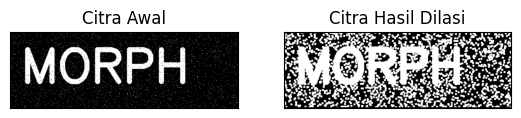

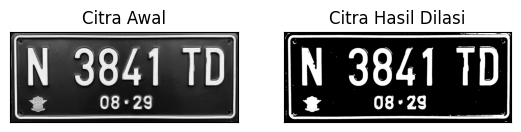

In [ ]:
def dilasi_citra(F, w):
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img_d = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w = 5
    imgD = dilasi_citra(thresh, w)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 4: Dilasi dengan Library OpenCV

[[1 1 1]
 [1 1 1]
 [1 1 1]]


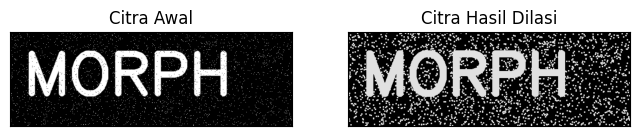

[[1 1 1]
 [1 1 1]
 [1 1 1]]


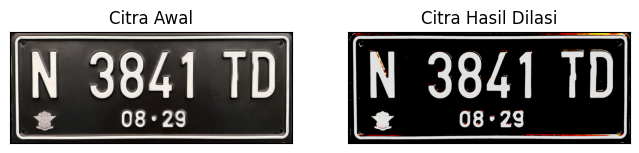

In [ ]:
kernel = np.ones((3, 3), np.uint16)
paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img = cv2.imread(path)
    # #img = cv2.imread('morp.jpg',0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    dilasi = cv2.dilate(thresh, kernel, iterations=1)
    print(kernel)

    plt.figure(figsize=(8, 4))
    plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 5: Erosi tanpa Library OpenCV

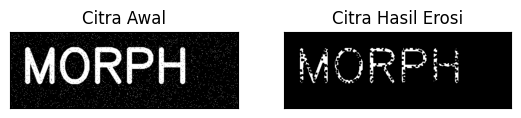

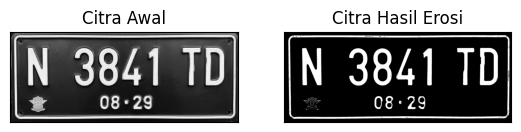

In [ ]:
def erosi_citra(F, k):
    # size image
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img_e = cv2.imread(path, 0)
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    k = 5
    imgE = erosi_citra(thresh1, k)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 6: Erosi dengan Library Morphology (Square 5x5)

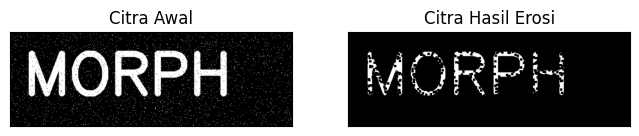

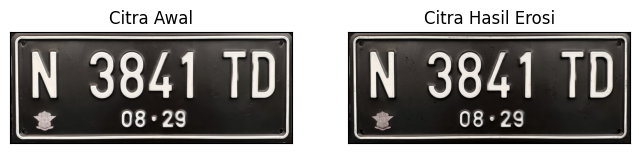

In [ ]:
# EROSI LIBRARY

kernel = np.ones((5, 5), np.uint8)
paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img = cv2.imread(path)
    erosion = cv2.erode(img, kernel, iterations=1)

    plt.figure(figsize=(8, 4))
    plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 7: Operasi Opening Tanpa Library Morphology

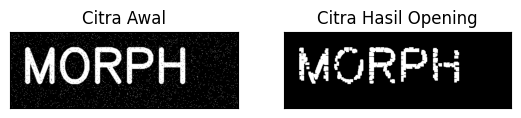

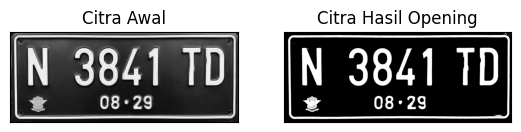

In [ ]:
paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img_o = cv2.imread(path, 0)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    k = 7
    imgO = dilasi_citra(erosi_citra(thresho, k), k)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_o, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgO, cmap='gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 7: Operasi Opening Menggunakan Library Morphology

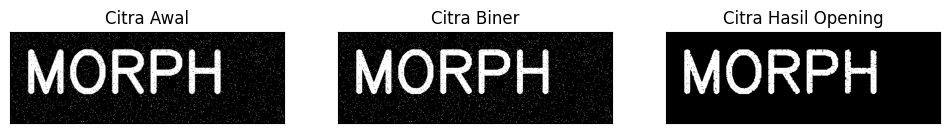

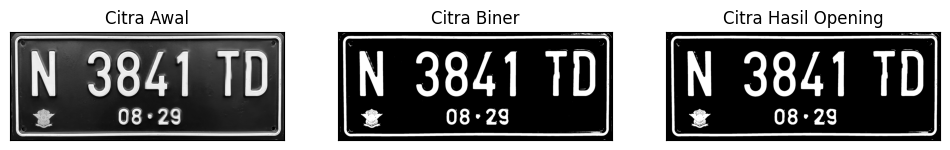

In [ ]:
paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    plt.figure(figsize=(12, 4))
    plt.subplot(131), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(thresh, cmap='gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133), plt.imshow(openn, cmap='gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 8: Operasi Closing Tanpa Library Morphology

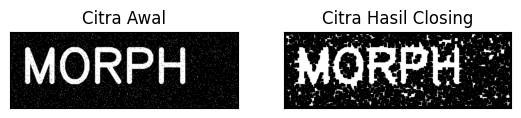

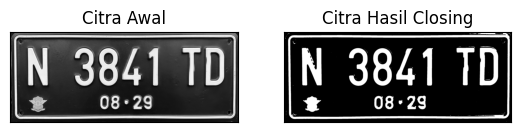

In [ ]:
paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img_c = cv2.imread(path, 0)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    k = 7
    imgC = erosi_citra(dilasi_citra(threshc, k), k)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_c, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgC, cmap='gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 8: Operasi Closing Dengan Library Morphology

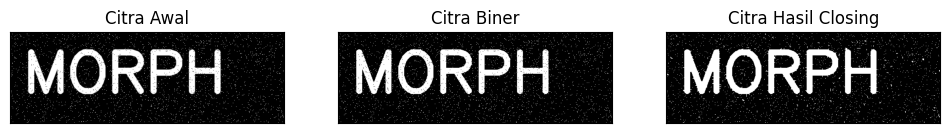

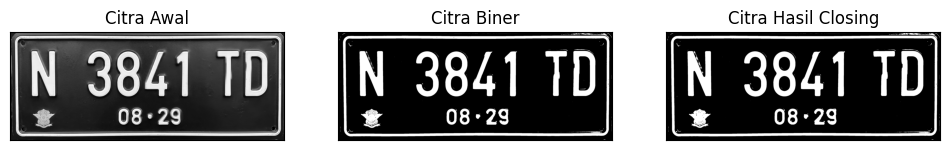

In [ ]:
paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    img = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    plt.figure(figsize=(12, 4))
    plt.subplot(131), plt.imshow(img, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(thresh, cmap='gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133), plt.imshow(closs, cmap='gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 9: Dilasi dengan Structuring Element Cross 3x3 dan 5x5

SED = Cross 3


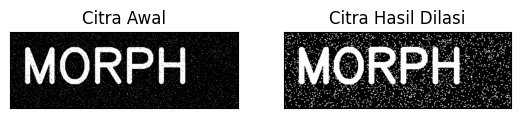

SED = Cross 5


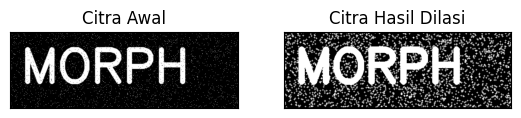

SED = Cross 3


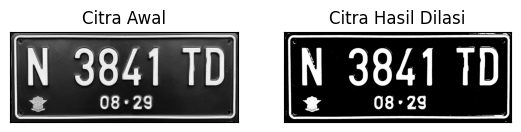

SED = Cross 5


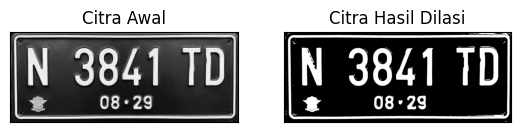

In [ ]:
# Dilasi Cross SED

def dilasi_citra_cross3(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)
    # Generate structure element dilasi (SED)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

def dilasi_citra_cross5(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    print('SED = Cross 3')
    img_d = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w = 3
    imgD = dilasi_citra_cross3(thresh, w)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

    print('SED = Cross 5')
    img_d = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w = 5
    imgD = dilasi_citra_cross5(thresh, w)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 10: Dilasi Circular SED

SED = Circle 3


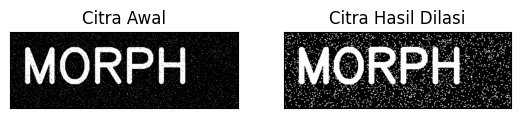

SED = Circle 5


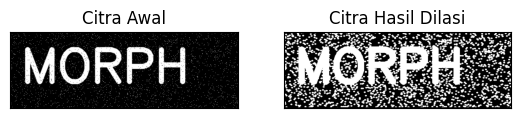

SED = Circle 3


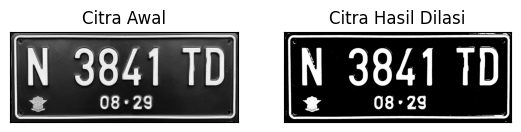

SED = Circle 5


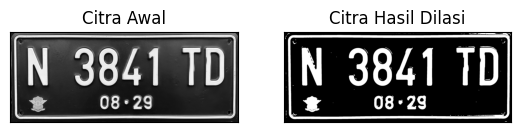

In [ ]:
# Dilasi Circular SED

def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    print('SED = Circle 3')
    img_d = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w = 3
    imgD = dilasi_citra(thresh, w)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

    print('SED = Circle 5')
    img_d = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w = 5
    imgD = dilasi_citra(thresh, w)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 11: Erosi Rectangle SE

SE = Rectangle 3x5


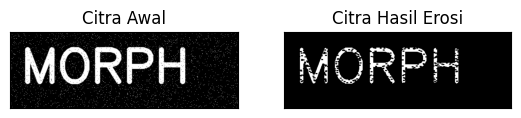

SE = Rectangle 5x7


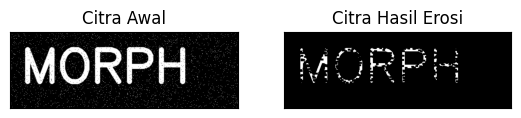

SE = Rectangle 3x5


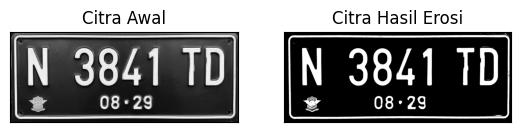

SE = Rectangle 5x7


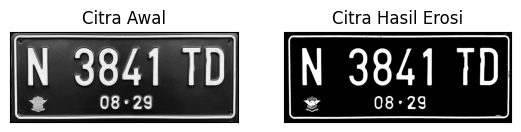

In [ ]:
def erosi_citra(F, p, l):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l)) # SE persegi panjang
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    # print(SE)
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    print('SE = Rectangle 3x5')
    img_e = cv2.imread(path, 0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p = 5
    l = 3
    imgE = erosi_citra(thresh1, p, l)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

    print('SE = Rectangle 5x7')
    img_e = cv2.imread(path, 0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p = 7
    l = 5
    imgE = erosi_citra(thresh1, p, l)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 12: Erosi Line Vertikal SE

SE = Line Vertikal 3


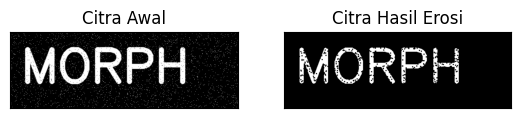

SE = Line Vertikal 5


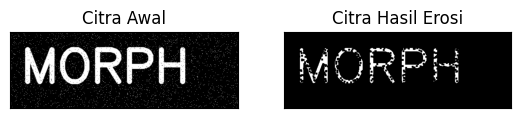

SE = Line Vertikal 3


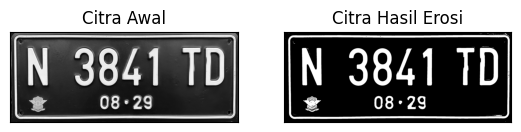

SE = Line Vertikal 5


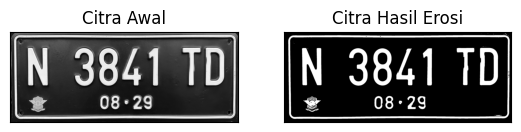

In [ ]:
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k)) # SE line vertikal
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

paths = ['/content/drive/MyDrive/PCVK2026/noisy_text.png', '/content/drive/MyDrive/PCVK2026/PlatNomer.jpg']

for path in paths:
    print('SE = Line Vertikal 3')
    img_e = cv2.imread(path, 0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k = 3
    imgE = erosi_citra(thresh1, k)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

    print('SE = Line Vertikal 5')
    img_e = cv2.imread(path, 0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k = 5
    imgE = erosi_citra(thresh1, k)

    plt.figure(figsize=(10, 4))
    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

### Nomor 13: Transformasi Top-Hat (Structuring Element 3x3)

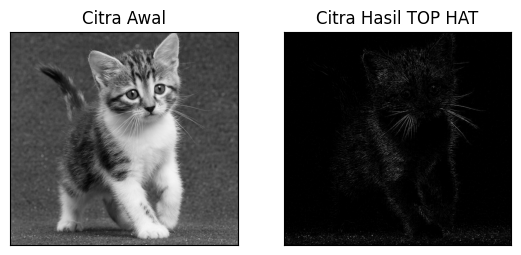

In [3]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK2026/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

# Display results
plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

### Nomor 14: Transformasi Black-Hat (Structuring Element 3x3)

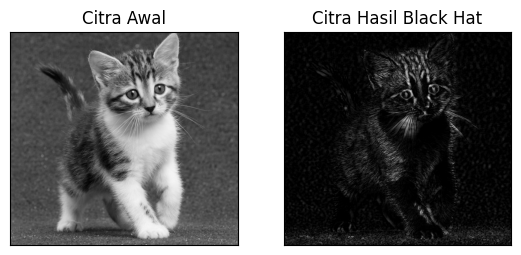

In [15]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK2026/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
# tophat_img = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(10, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

### Nomor 15: Skeletonization pada Citra Biner

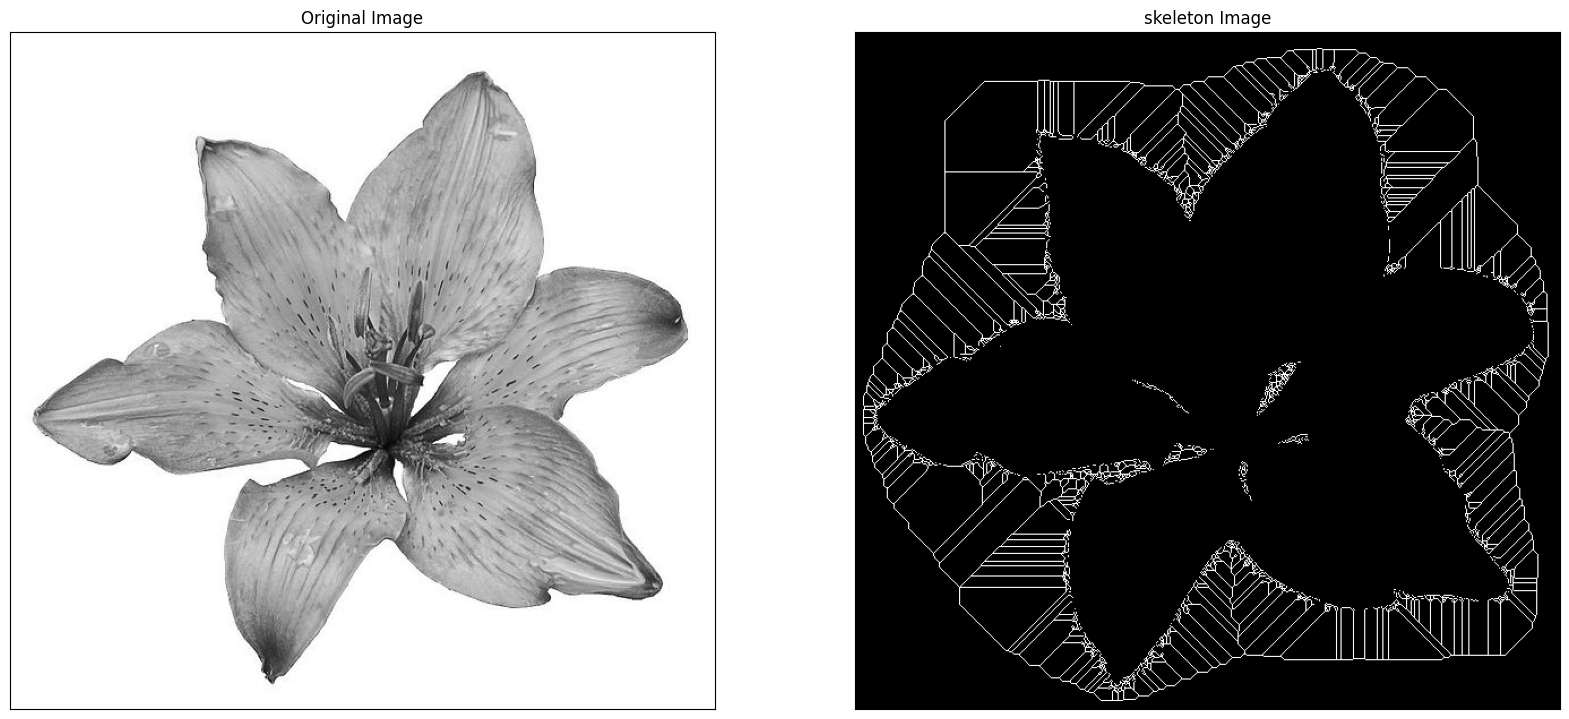

In [6]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/PCVK2026/lily.jpg', 0)
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

plt.figure(figsize=(20, 20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary_and_bin_skeleton.png")
plt.show()

### Nomor 16: Skeleton pada Citra Hasil Inversi

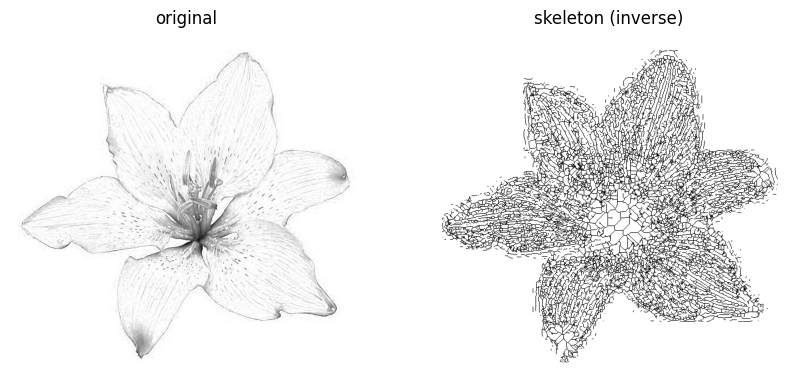

In [11]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/PCVK2026/lily.jpg')[:, :, 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(10, 10))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

### Nomor 17: Thinning Memakai morphology.thin()

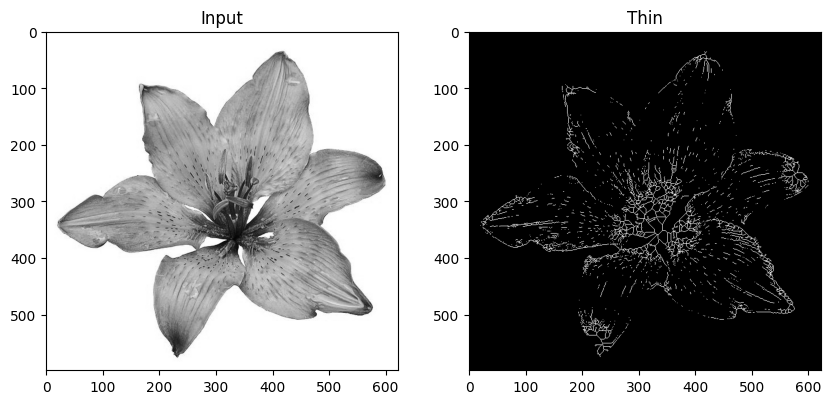

In [12]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK2026/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 10))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()